# Project 2: Portfolio Optimization, PCA, and Dynamic Allocation

**Due October 23**

In this project, you will implement generalized deviation-risk optimization, mean--variance and PCA factor models, validation/test portfolio selection, and a multi-period portfolio optimization extension.

Use the supplied `Project2_returns.csv`. You may use NumPy, pandas, Matplotlib, and CVXPY, with a suitable convex solver.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import time
from pathlib import Path

ANNUALIZATION = 252


## Data

Use these 16 assets in the given order:

`GOOG, TSLA, AAPL, GS, A, AAP, MSFT, AMZN, NVDA, JPM, XOM, JNJ, PG, WMT, CAT, BA`.

- **Training:** 2017-01-01 to 2018-12-31
- **Validation:** 2019-01-01 to 2019-06-30
- **Test:** 2019-07-01 to 2019-12-31

For asset $j$ on day $s$, define the open-to-close return

$$
r_{j,s}=\frac{p^c_{j,s}-p^o_{j,s}}{p^o_{j,s}}.
$$

For any estimation sample, let $\bar r$ and $\widehat\Sigma$ denote the sample mean and covariance of the **daily** returns (use denominator $N-1$). Use the annualized inputs

$$
\mu=252\bar r,\qquad Q=252\widehat\Sigma.
$$

All candidate models in Tasks 1--2 must be fitted using training data only. Task 3 uses the original daily returns for P&L. Task 4 uses separate quarterly estimates within the training period.

Portfolio weights satisfy $x\ge0$ and $\mathbf1^\top x=1$.


In [2]:
asset_lst = [
    'GOOG', 'TSLA', 'AAPL', 'GS',
    'A', 'AAP', 'MSFT', 'AMZN',
    'NVDA', 'JPM', 'XOM', 'JNJ',
    'PG', 'WMT', 'CAT', 'BA'
]

data_path = Path('Project2_returns.csv')

if data_path.exists():
    # Preferred: the supplied fixed sample of daily open-to-close returns.
    returns = pd.read_csv(data_path, parse_dates=['Date'], index_col='Date')
    missing_assets = sorted(set(asset_lst) - set(returns.columns))
    if missing_assets:
        raise ValueError(f'Missing assets in the supplied data: {missing_assets}')
    returns = returns.reindex(columns=asset_lst)
    data_source = str(data_path)
else:
    import yfinance as yfin

    # yfinance treats the end date as exclusive.
    data = yfin.download(
        asset_lst,
        start='2017-01-01',
        end='2020-01-01',
        auto_adjust=True,
        progress=False
    )
    if data.empty:
        raise RuntimeError(
            'The download returned no data. Place the supplied '
            'Project2_returns.csv beside this notebook and rerun.'
        )

    open_prices = data['Open'].reindex(columns=asset_lst).dropna(how='any')
    close_prices = data['Close'].reindex(columns=asset_lst).dropna(how='any')
    common_dates = open_prices.index.intersection(close_prices.index)
    open_prices = open_prices.loc[common_dates]
    close_prices = close_prices.loc[common_dates]
    returns = close_prices / open_prices - 1
    data_source = 'yfinance download'

returns = returns.sort_index().loc['2017-01-01':'2019-12-31']
returns = returns.replace([np.inf, -np.inf], np.nan).dropna(how='any')
assert returns.columns.tolist() == asset_lst
assert returns.index.is_unique
assert not returns.empty
assert np.isfinite(returns.to_numpy()).all()

train_returns = returns.loc[
    (returns.index >= '2017-01-01') & (returns.index < '2019-01-01')
].copy()
validation_returns = returns.loc[
    (returns.index >= '2019-01-01') & (returns.index < '2019-07-01')
].copy()
test_returns = returns.loc[
    (returns.index >= '2019-07-01') & (returns.index < '2020-01-01')
].copy()

if any(frame.empty for frame in (train_returns, validation_returns, test_returns)):
    raise ValueError('At least one required data period is empty.')

print('Data source:', data_source)
print('Training shape:', train_returns.shape)
print('Validation shape:', validation_returns.shape)
print('Test shape:', test_returns.shape)
print(train_returns.head())

Data source: Project2_returns.csv
Training shape: (502, 16)
Validation shape: (124, 16)
Test shape: (128, 16)
                GOOG      TSLA      AAPL        GS         A       AAP  \
Date                                                                     
2017-01-03  0.009412  0.009913  0.003022 -0.004656  0.012192 -0.001054   
2017-01-04 -0.001852  0.056997  0.001467  0.007000  0.003622  0.009567   
2017-01-05  0.010101  0.001457  0.005952 -0.005768 -0.010839  0.005911   
2017-01-06  0.013694  0.009166  0.009676  0.010772  0.029166 -0.009865   
2017-01-09  0.000310  0.010089  0.008817 -0.001480  0.002708 -0.003117   

                MSFT      AMZN      NVDA       JPM       XOM       JNJ  \
Date                                                                     
2017-01-03 -0.003344 -0.005607 -0.022893 -0.001259 -0.000550  0.000518   
2017-01-04 -0.002881 -0.001595  0.009574 -0.000575 -0.013499  0.001299   
2017-01-05  0.001769  0.024818 -0.026691 -0.008064 -0.018184  0.007414   
2

# Task 1: Generalized deviation-risk portfolio optimization

For $p\ge1$, define

$$
\rho_p(x)=\left[\frac1N\sum_{s=1}^{N}
|(r_s-\bar r)^\top x|^p\right]^{1/p},
\qquad
\widetilde\rho_p(x)=\sqrt{252}\,\rho_p(x),
$$

where $N$ is the number of training observations and $\bar r$ is the daily training mean. The latter is a scaled daily-deviation measure.

Solve

$$
\min_x\quad -\mu^\top x+\lambda\widetilde\rho_p(x)
\quad\text{s.t.}\quad x\ge0,\ \mathbf1^\top x=1.
$$

Use $p\in\{2,3,4,6\}$ and at least **25 values of $\lambda$ for each $p$**, chosen using training data.

### Requirements

1. Implement the optimization and store the weights and parameters for each candidate.
2. Plot the training return--deviation-risk tradeoff for representative values of $p$.
3. Compare the resulting portfolios and discuss the effect of $p$. Also report their annualized volatility under the training covariance $Q$.


In [3]:
# Task 1: your generalized deviation-risk implementation


# Task 2: Static mean--variance and PCA factor models

## Task 2(a): Full-covariance mean--variance optimization

Using annualized training estimates $\mu$ and $Q$, solve

$$
\min_x\quad \lambda x^\top Qx-\mu^\top x
\quad\text{s.t.}\quad x\ge0,\ \mathbf1^\top x=1.
$$

### Requirements

1. Use at least **50 values of $\lambda$**, chosen using training data, and store the resulting portfolios as candidates for Task 3.
2. Plot the annualized expected return $\mu^\top x$ against volatility $\sqrt{x^\top Qx}$.


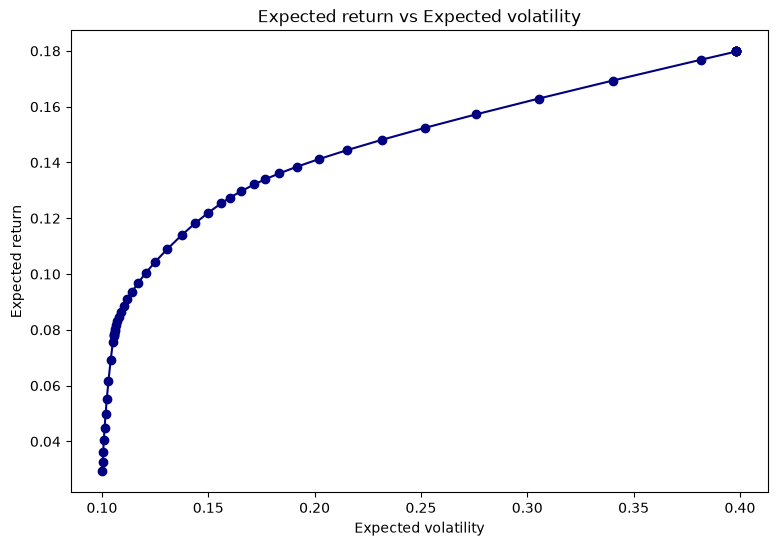

,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,0.00e+00,1.00e+00,0.00e+00,2.32e-22,0.00e+00,0.00e+00,9.29e-24,0.00e+00,8.45e-24,0.00e+00,9.71e-24,0.00e+00,6.50e-23,0.00e+00,9.64e-24,0.00e+00
1,1.15e-01,2.83e-23,1.00e+00,0.00e+00,3.86e-25,1.97e-25,6.84e-27,0.00e+00,8.81e-25,4.46e-22,1.42e-25,1.11e-22,2.74e-23,5.49e-23,0.00e+00,1.12e-22,5.60e-23
2,1.33e-01,0.00e+00,1.00e+00,0.00e+00,1.67e-22,5.57e-23,0.00e+00,5.60e-23,5.64e-23,0.00e+00,0.00e+00,5.52e-23,0.00e+00,0.00e+00,0.00e+00,5.62e-23,0.00e+00
3,1.53e-01,1.38e-23,1.00e+00,0.00e+00,1.81e-22,6.99e-23,0.00e+00,0.00e+00,6.90e-23,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.48e-23,8.43e-23,0.00e+00,0.00e+00
4,1.76e-01,2.82e-23,1.00e+00,2.80e-23,3.25e-25,1.52e-25,0.00e+00,0.00e+00,7.95e-25,1.58e-24,9.69e-26,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.12e-22,0.00e+00
5,2.02e-01,0.00e+00,1.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,4.63e-26,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
6,2.33e-01,0.00e+00,9.55e-01,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,4.52e-02,0.00e+00,0.00e+00
7,2.68e-01,4.89e-23,8.40e-01,2.19e-23,5.24e-23,5.16e-23,1.66e-22,1.05e-22,0.00e+00,4.13e-23,5.26e-23,5.41e-23,2.71e-23,2.64e-23,1.60e-01,5.09e-23,0.00e+00
8,3.09e-01,3.62e-23,7.41e-01,0.00e+00,4.33e-23,1.53e-22,1.60e-22,3.74e-23,1.44e-22,0.00e+00,4.41e-23,4.74e-23,3.54e-23,2.04e-23,2.59e-01,0.00e+00,6.84e-23
9,3.56e-01,0.00e+00,6.54e-01,7.76e-23,0.00e+00,2.07e-23,1.54e-23,0.00e+00,1.36e-22,2.88e-23,0.00e+00,1.28e-22,0.00e+00,0.00e+00,3.46e-01,2.22e-23,0.00e+00


In [4]:
# Task 2(a): your full-covariance mean--variance implementation
from matplotlib.pyplot import subplots
# Function for convex optimization
def solve_opt(lam,df_train,mu,Q):
    # Define variables for cvxpy
    n=df_train.shape[1]
    x=cp.Variable(n)
    # Setting up objective function
    objective=cp.Minimize(lam*cp.quad_form(x,Q)-mu@x)
    # Setting up constraints 
    constraints=[x>=0,cp.sum(x)==1]
    # Solving the optimization
    prob=cp.Problem(objective, constraints)
    prob.solve()
    if prob.status=='optimal':
        # Cliping the negative values
        x=x.value
        x = np.clip(x, 0, None) 
        x = x / x.sum()
        # Return the resulting portfolio X
        return x
    else:
        print('no optimal solution')
        return np.zeros(n)
    
# Function for looping across multiple lambda values
def loop_lambda(df_train,mu,Q):
    # Define a list of 50 lambda values,from 10^(-2) to 10^(2) to cover a reasonable range of lambda, equal step under logspace, to allocate enough points for the sensitve range 
    lambda_vals=np.logspace(-1,2,50)
    # Define a list for the resulting X for each lambda
    x_results=[]
    # call solve_opt, store result
    for idx,lam in enumerate(lambda_vals):
        result=solve_opt(lam,df_train,mu,Q)
        x_results.append(result)
    # Consolidate array of results and corresponding lambda values in to a dataframe, return the df
    df_results=pd.DataFrame({'lambda values':lambda_vals,'optimal allocation':x_results})
    return df_results,x_results
    
# Function for plotting the annualized return against volatility
def plot_return_vol(df_results,x_results,mu,Q):
    # Compute the return and volatility for each x
    df_results['portfolio_return']=x_results@mu #50xn@nx1
    df_results['portfolio_volatility']=np.sqrt(np.diag(x_results@Q@np.array(x_results).T)) #50xn@nxn@nx50
    # plot 
    ax=subplots(figsize=(9,6))[1]
    ax.plot(df_results['portfolio_volatility'], df_results['portfolio_return'],marker='o', color='navy')
    ax.set_title('Expected return vs Expected volatility')
    ax.set_xlabel('Expected volatility')
    ax.set_ylabel('Expected return')
    plt.show()
    return df_results
    
# A function of displaying the optimal allocation across assets
def display_allocation(df_train,df_results):
    # extract 15 assets names
    cols=df_train.columns
    # convert original array of list for asset allocation into matrix (50x15)
    weights=df_results['optimal allocation'].tolist()
    df_allocation=pd.DataFrame(weights,columns=cols)
    # insert a lambda value column at position 0
    df_allocation.insert(0,'lambda values',df_results['lambda values'])
    return df_allocation
                            


# Main function
# Compute mu and Q
df_train=train_returns.copy()
r_mean=df_train.mean()
sigma=df_train.cov()
mu=ANNUALIZATION*r_mean
Q=ANNUALIZATION*sigma
# Converting mu and Q from pd to np array
mu=np.array(mu).flatten()
Q=np.array(Q)
df_results,x_results=loop_lambda(df_train,mu,Q)
# The full results df with return and vol
df_results=plot_return_vol(df_results,x_results,mu,Q)
# A better organized df of results (with lambda value, all 16 assets weight as columns)
df_allocation=display_allocation(df_train,df_results)
# Formatting the table for display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
df_allocation.style.format("{:.2e}").background_gradient(cmap='Blues',axis=1, subset=df_allocation.columns[1:]).set_properties(**{'white-space': 'nowrap', 'font-size': '10px'})

## Discussion:
1. The algorithm selected equal logspaced value for $\lambda$ to recover the full shape of the efficient frontier, so that it could take more concentrated values in the range where results are sensitive to $\lambda$ changes. The two terms of portfolio volatility and expected return, has the scale in $10^{-2}$ and $10^{-1}$ respectively, so the corresponding range for $\lambda$ could be $10^{-1}$ to $10^{2}$, so that when $\lambda$ is close to the lower bound, the volatility penalty term is negligible, the optimizer focus of maximizing return, locating on the upper right corner of the eifficient frontier, when $\lambda$ is close to upper bound, the two terms have similar magnitude, the points moves towards the minimum variance portfolio. Optimal portfolio weightings are listed above, some solver rounding error of negative values are cliped, with the remaining weights normalized, no sparsity regulation is enforced on the small positive values to show differences between portfolios when $\lambda$ is in the range where results are not sensitive to its changes.

## Output from this section:
- **df_results**: A dataframe with the full result from optimization (but weightings are stored as list in every cell in the column 'optimal allocation'),including the return and volatility,across 50 $\lambda$ values.
- **df_allocation**: A dataframe with weighting of each asset in a seperate column, across 50 $\lambda$ values

## Task 2(b): Static PCA factor model

Apply **covariance PCA** to the training returns (without standardizing individual assets). Use the annualized covariance decomposition

$$
Q=W\Lambda W^\top,\qquad
\Lambda_K=\operatorname{diag}(\ell_1,\ldots,\ell_K),\qquad
W_K=(w^{(1)},\ldots,w^{(K)}).
$$

Construct the PCA factor covariance model

$$
D_K=\operatorname{diag}(Q-W_K\Lambda_KW_K^\top),
\qquad
Q_{\mathrm{PCA},K}=W_K\Lambda_KW_K^\top+D_K.
$$

Introducing $y=W_K^\top x$, solve

$$
\min_{x,y}\quad
\lambda\left(y^\top\Lambda_K y+x^\top D_Kx\right)-\mu^\top x
$$

subject to

$$
x\ge0,\qquad \mathbf1^\top x=1,\qquad y=W_K^\top x.
$$

### Requirements

1. Plot individual and cumulative explained-variance ratios. Let $K_{80}$ be the smallest $K$ explaining at least 80% of the training variance.
2. Use at least **three** choices of $K$, including $K_{80}$. For each, report the relative covariance error $\|Q-Q_{\mathrm{PCA},K}\|_F/\|Q\|_F$.
3. For each selected $K$, solve for at least **50 values of $\lambda$**, and retain the portfolios for Task 3.
4. Compare the training portfolio risk--return tradeoffs under the **same full covariance $Q$**. Discuss how $K$ affects the approximation and the optimal portfolios.
5. For one $K$ and $\lambda$, verify the factor formulation against directly optimizing with $Q_{\mathrm{PCA},K}$.


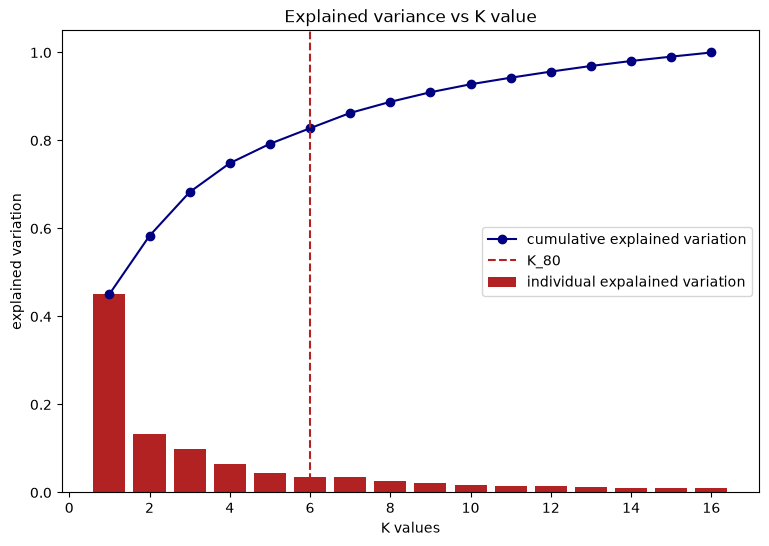

In [5]:
# Task 2(b): your static PCA factor-model implementation
# Function for PCA through Eigenvector decomposition
def PCA(Q):
    # Solve for eigenvector and eigenvalues
    eigenvalues,eigenvectors=np.linalg.eigh(Q)
    # Sort the results,idx as the descending index of eigenvalues matrix,sort eigenvalues and eigenvectors base on the idx
    idx=np.argsort(eigenvalues)[::-1]
    eigenvalues=eigenvalues[idx]
    eigenvectors=eigenvectors[:,idx]
    # Assign variable names to be in line with the problem setting
    cap_lam=np.diag(eigenvalues)
    W=eigenvectors
    # Find K80
    cumsum=np.cumsum(eigenvalues)
    sum_val=np.sum(eigenvalues)
    explained_var=cumsum/sum_val
    K_80=np.argmax(explained_var>=0.8)+1
    df_explained_var=pd.DataFrame({'K value':np.arange(1,len(eigenvalues)+1),'explained variation':explained_var})
    # Return K80,eigenvector and eigenvalues
    return K_80, cap_lam, W,df_explained_var
    
# Function for constructing Qpca for a given K value
def construct_Q_PCA(K,Q,cap_lam,W):
    # For a given value of K, reconstruct D_K and Q_PCA,K
    eigenvalues=np.diag(cap_lam)
    lam_K=np.diag(eigenvalues[:K]) # KxK
    W_K=W[:,:K] #nxK
    D_K=np.diag(np.diag(Q-W_K@lam_K@W_K.T)) # nxn
    Q_PCA=W_K@lam_K@W_K.T+D_K # nxn
    # Compute the relative covariance error
    rel_cov_error=np.linalg.norm(Q - Q_PCA, 'fro') / np.linalg.norm(Q, 'fro')
    # return a dictionary of results
    dict_result={
        'Q_PCA':Q_PCA,
        'W_K':W_K,
        'lam_K':lam_K,
        'D_K':D_K,
        'rel_cov_err':rel_cov_error}
    return dict_result
    
def opt_pca(K,lam,Q_PCA,W_K,lam_K,D_K,df_train,mu): # For values of lambda&K
    # Define variable x and y
    n=df_train.shape[1]
    x=cp.Variable(n)
    y=cp.Variable(K)
    # Define objective function
    objective=cp.Minimize(lam*(cp.quad_form(y,lam_K)+cp.quad_form(x,D_K))-mu@x)
    # Define constraints
    constraints=[ x>=0, cp.sum(x)==1, y==W_K.T@x]
    # Solve the problem, return x,y
    prob=cp.Problem(objective, constraints)
    prob.solve()
    if prob.status=='optimal':
        # Clip negative x values and normalize, recompute y accordingly
        x=x.value
        x=np.clip(x,0,None)
        x=x/np.sum(x)
        y=W_K.T@x
        # Return the resulting portfolio X
        return x,y
    else:
        print('no optimal solution')
        return np.zeros(n),np.zeros(K)

def direct_opt(K,lam,Q_PCA,df_train,mu): # optimization with Q_PCA without defining y)
    # Define variable x and y
    n=df_train.shape[1]
    x=cp.Variable(n)
    # Define objective function
    objective=cp.Minimize(lam*cp.quad_form(x,Q_PCA)-mu@x)
    # Define constraints
    constraints=[ x>=0, cp.sum(x)==1]
    # Solve the problem, return x
    prob=cp.Problem(objective, constraints)
    prob.solve()
    if prob.status=='optimal':
        # Clip negative x values and normalize
        x=x.value
        x=np.clip(x,0,None)
        x=x/np.sum(x)
        # Return the resulting portfolio X
        return x
    else:
        print('no optimal solution')
        return np.zeros(n)

def store_results(Q,mu,df_results,df_train,K_80, cap_lam):
    # Define some K along with K80
    lst_K=[1,K_80,9]
    # Extract lambda values from df_results in 2a)
    lam_values=df_results['lambda values'].values
    # Create a list for the row datas
    rows=[]
    cov_err=[] # a list for rel_cov_error result across K
    # call construct_Q_PCA for each K
    for i,K in enumerate(lst_K):
        dict_result=construct_Q_PCA(K,Q,cap_lam,W)
        rel_cov_error=dict_result['rel_cov_err']
        cov_err.append({
            'K values':K,
            'rel_cov_err':rel_cov_error})
        # Extract variables from the dictionary
        Q_PCA=dict_result['Q_PCA']
        W_K=dict_result['W_K']
        lam_K=dict_result['lam_K']
        D_K=dict_result['D_K']
        for idx,lam in enumerate(lam_values):
            # For each Lambda, Call opt_pca for the results
            x,y=opt_pca(K,lam,Q_PCA,W_K,lam_K,D_K,df_train,mu) #nx1,Kx1
            # Also do a direct OPT on Q_PCA without defining y
            x_direct=direct_opt(K,lam,Q_PCA,df_train,mu)
            portfolio_return=mu.T@x
            portfolio_vol=np.sqrt(x.T@Q@x)
            direct_return=mu.T@x_direct
            direct_vol=np.sqrt(x_direct.T@Q@x_direct)
            # Store the results in a dictionary
            row_data={
            'K value':K,
            'lambda values':lam,
            'Relative covariance error:':rel_cov_error,
            'optimal allocation':x.tolist(),
            'PC score':y.tolist(),
            'portfolio_return':portfolio_return,
            'portfolio_volatility':portfolio_vol,
            'Allocation from direct OPT':x_direct.tolist(),
            'return(direct)':direct_return,
            'volatility(direct)':direct_vol}
            rows.append(row_data)
    df_results_PCA=pd.DataFrame(rows)
    df_cov_err=pd.DataFrame(cov_err)
    return df_results_PCA,df_cov_err

# Function of plot
def plot_explained_var(df_explained_var,K_80):
    # Process the cumulative explained variation df for the individual explained variance
    individual_var=df_explained_var['explained variation'].diff()
    individual_var[0]=df_explained_var['explained variation'][0]
    ax=subplots(figsize=(9,6))[1]
    ax.plot(df_explained_var['K value'], df_explained_var['explained variation'],marker='o', color='navy',label='cumulative explained variation')
    ax.bar(df_explained_var['K value'],individual_var,color='firebrick',label='individual expalained variation')
    ax.axvline(x=K_80,color='firebrick',linestyle='--',label='K_80')
    ax.set_title('Explained variance vs K value')
    ax.set_xlabel('K values')
    ax.set_ylabel('explained variation')
    plt.legend()
    plt.show()
    return 
    
# Function of comparing risk return trade off across different K
def evaluation(df_results_PCA,df_results):
    # plot efficient frontier of 3 K values, and one from a) with full Q optimized results
    ax=subplots(figsize=(9,6))[1]
    lst_K=df_results_PCA['K value'].unique()
    ax.plot(df_results['portfolio_volatility'], df_results['portfolio_return'],color='navy',label='full Q result')
    COLOR=['firebrick','steelblue','rebeccapurple']
    for idx,K in enumerate(lst_K):
        mask=df_results_PCA['K value']==K
        ax.plot(df_results_PCA[mask]['portfolio_volatility'], df_results_PCA[mask]['portfolio_return'],color=COLOR[idx],label=f'K value {K}')
    ax.set_title('return and variance trade-off across different K values')
    ax.set_xlabel('Portfolio volatility')
    ax.set_ylabel('Portfolio return')
    plt.legend()
    plt.show()
    # Plot sparsity of allocation across K through inverse HHI
    ax1=subplots(figsize=(9,6))[1]
    lambdas=df_results_PCA['lambda values'][:50]
    # 2a)'s result 
    effective_asset=[]
    for w in df_results['optimal allocation']:
        w=np.array(w)
        eff=1/np.sum(w**2) if np.sum(w**2) >0 else 0
        effective_asset.append(eff)
    ax1.plot(lambdas,effective_asset,marker='o',color='navy',label='full Q result')
    for idx,K in enumerate(lst_K):
         mask=df_results_PCA['K value']==K
         effective_asset=[]
         for w in df_results_PCA[mask]['optimal allocation']:
             w=np.array(w)
             eff=1/np.sum(w**2) if np.sum(w**2) >0 else 0
             effective_asset.append(eff)
         ax1.plot(lambdas,effective_asset,marker='o',color=COLOR[idx],label=f'K value {K}')
    ax1.set_xscale('log')
    ax1.set_xlabel('lambda values')
    ax1.set_ylabel('effective number of assets')
    plt.legend()
    plt.show()
    return

# Displaying the optimal portfolios
def display_table(df_train,df,col_name):
    # Resetting index of df for later K values
    df=df.reset_index(drop=True)
    # extract 15 assets names
    cols=df_train.columns
    # convert original array of list for asset allocation into matrix (50x15)
    weights=df[col_name].tolist()
    df_allocation_PCA=pd.DataFrame(weights,columns=cols)
    # insert a lambda value column at position 0
    df_allocation_PCA.insert(0,'lambda values',df['lambda values'])
    return df_allocation_PCA
    
# Main function 
# Run PCA
K_80, cap_lam, W,df_explained_var=PCA(Q)
# plot
plot_explained_var(df_explained_var,K_80)
# Get the results across lam and K value pairs and store them
df_results_PCA,df_cov_err=store_results(Q,mu,df_results,df_train,K_80, cap_lam)


### Discussion 1:
The cumulative explained variation by the PC's and their individual explained variations are listed above, the 1st PC explained around 45% of variation in the data, with $K_{80}$ being 6

### Discussion 2:
The three values chosen for $K$ are $1,6,9$, with $K_{80}=6$, the relative covariance error are listed as follows, the larger is the $K$ value, the more variation is preserved from original $Q$, si relative covariance error decline.

In [6]:
# Comparison of K's effect through evaluating relative covariance error values and the optimal allocation weights 
# Output the relative covariance error
df_cov_err.style.format("{:.2e}").set_properties(**{'white-space': 'nowrap', 'font-size': '15px'})


,K values,rel_cov_err
0,1.00e+00,1.99e-01
1,6.00e+00,6.65e-02
2,9.00e+00,4.28e-02


### Discussion 3:
Same value in Task 2a) are chose for $\lambda$, portolios are shown below, one table per value of $K$, these are result from  the factor formulated optimization, with also an algorithm to compare the the results of direct optimization from $Q_{PCA,k}$ and allow relative error upto $10^{-5}$ and absolute error up to $10^{-8}$ to allow for rounding errors. All values from the 150 lines are considered the same, output of verification results are printed under title for each of the three tables.

In [7]:
# Displaying the optimal portfolios for each K across 50 lambda values,check the results with direct opt without introducing Y
from IPython.display import display
K_values=df_results_PCA['K value'].unique()
# Create a dictionary to store the df_allocation_PCA for each value of K:
dict_allocation_PCA={}
for K in K_values:
    mask=df_results_PCA['K value']==K
    df_allocation_PCA=display_table(df_train,df_results_PCA[mask],'optimal allocation')
    df_direct=display_table(df_train,df_results_PCA[mask],'Allocation from direct OPT')
    # Store df_allocation_PCA in dictionary
    dict_allocation_PCA[K]=df_allocation_PCA
    print(f'------Optimal allocation with K={K}-----------')
    # Compare the results of two optimization
    if np.allclose(df_allocation_PCA,df_direct,rtol=1e-05,atol=1e-08)==True:
        print(f'------the result is the same with direct optimization without y-----------')
    styled_table = df_allocation_PCA.style.format("{:.2e}")\
        .background_gradient(cmap='Blues',axis=1,subset=df_allocation_PCA.columns[1:])\
        .set_properties(**{'white-space': 'nowrap', 'font-size': '10px'})
    display(styled_table)

------Optimal allocation with K=1-----------
------the result is the same with direct optimization without y-----------


,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,6.57e-24,1.00e+00,6.20e-23,6.21e-23,6.20e-23,6.21e-23,6.21e-23,6.22e-23,6.27e-23,1.73e-22,6.18e-23,8.95e-23,1.17e-22,8.96e-23,1.73e-22,8.99e-23
1,1.15e-01,2.36e-23,1.00e+00,5.18e-23,2.74e-22,1.63e-22,0.00e+00,5.15e-23,0.00e+00,4.91e-23,1.63e-22,5.31e-23,2.55e-23,1.09e-22,2.54e-23,5.15e-23,2.39e-23
2,1.33e-01,5.38e-23,1.00e+00,8.21e-23,0.00e+00,1.66e-22,2.78e-22,5.39e-23,0.00e+00,5.12e-23,5.49e-23,5.58e-23,2.82e-23,8.40e-23,4.20e-23,1.65e-22,2.64e-23
3,1.53e-01,9.94e-23,1.00e+00,4.48e-23,0.00e+00,0.00e+00,2.97e-22,1.83e-22,7.04e-23,2.89e-22,7.37e-23,7.52e-23,7.56e-23,7.61e-23,8.93e-23,0.00e+00,7.22e-23
4,1.76e-01,4.23e-23,1.00e+00,1.55e-23,4.36e-23,4.38e-23,4.55e-23,1.54e-22,1.52e-22,3.80e-23,4.42e-23,0.00e+00,1.81e-23,4.64e-23,3.19e-23,4.27e-23,4.29e-23
5,2.02e-01,4.44e-23,1.00e+00,4.54e-23,0.00e+00,0.00e+00,1.59e-22,1.56e-22,4.31e-23,1.50e-22,4.65e-23,4.81e-23,4.84e-23,4.90e-23,6.91e-23,0.00e+00,5.88e-23
6,2.33e-01,5.56e-23,9.73e-01,3.87e-24,3.32e-23,1.45e-22,0.00e+00,2.90e-23,2.29e-23,0.00e+00,0.00e+00,1.53e-22,7.10e-23,4.53e-23,2.66e-02,1.40e-22,1.61e-23
7,2.68e-01,2.11e-23,8.54e-01,2.32e-23,2.41e-23,2.45e-23,2.86e-23,0.00e+00,1.85e-23,1.04e-23,2.57e-23,2.89e-23,1.86e-24,3.07e-23,1.46e-01,0.00e+00,0.00e+00
8,3.09e-01,0.00e+00,7.51e-01,4.88e-24,2.00e-22,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,2.51e-23,1.23e-23,2.49e-01,0.00e+00,4.05e-24
9,3.56e-01,4.92e-24,6.61e-01,4.25e-24,2.54e-22,3.16e-23,1.42e-22,8.80e-23,3.37e-23,0.00e+00,1.42e-22,1.41e-22,1.61e-23,1.80e-24,3.39e-01,1.44e-22,3.24e-23


------Optimal allocation with K=6-----------
------the result is the same with direct optimization without y-----------


,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,1.36e-22,1.00e+00,1.06e-22,1.64e-22,1.64e-22,0.00e+00,1.64e-22,0.00e+00,0.00e+00,1.63e-22,2.73e-22,1.08e-22,2.15e-22,1.63e-22,5.35e-23,1.66e-22
1,1.15e-01,1.97e-22,1.00e+00,2.24e-22,1.71e-22,6.03e-23,3.95e-22,3.92e-22,0.00e+00,1.64e-22,1.71e-22,1.72e-22,1.74e-22,1.71e-22,1.87e-22,5.94e-23,1.44e-22
2,1.33e-01,1.00e-22,1.00e+00,9.88e-23,7.32e-23,1.84e-22,7.23e-23,7.28e-23,7.40e-23,0.00e+00,1.83e-22,0.00e+00,7.26e-23,4.06e-23,9.94e-23,2.96e-22,7.54e-23
3,1.53e-01,1.88e-22,1.00e+00,1.57e-22,6.60e-22,1.04e-22,2.14e-22,0.00e+00,2.18e-22,4.43e-22,1.02e-22,2.11e-22,2.13e-22,1.80e-22,1.56e-22,1.06e-22,2.18e-22
4,1.76e-01,4.62e-23,1.00e+00,7.32e-23,2.97e-22,7.56e-23,7.59e-23,1.85e-22,0.00e+00,0.00e+00,7.45e-23,7.48e-23,7.68e-23,1.01e-22,8.97e-23,2.97e-22,7.70e-23
5,2.02e-01,1.46e-22,1.00e+00,8.92e-23,1.47e-22,2.58e-22,1.48e-22,2.02e-22,1.46e-22,1.43e-22,3.68e-22,1.47e-22,1.49e-22,8.93e-23,1.44e-22,0.00e+00,1.35e-22
6,2.33e-01,1.15e-22,9.55e-01,8.92e-23,1.46e-22,1.47e-23,4.68e-23,5.98e-23,0.00e+00,0.00e+00,2.54e-22,1.43e-22,4.79e-23,1.08e-22,4.49e-02,2.54e-22,1.25e-22
7,2.68e-01,8.79e-23,8.40e-01,6.07e-23,5.52e-22,2.05e-22,1.82e-24,3.19e-23,1.92e-22,0.00e+00,0.00e+00,1.04e-22,6.78e-23,1.27e-22,1.60e-01,0.00e+00,6.58e-23
8,3.09e-01,5.11e-23,7.41e-01,2.68e-23,7.15e-23,0.00e+00,8.33e-23,5.23e-23,4.18e-23,3.87e-24,7.19e-23,0.00e+00,4.45e-23,1.02e-22,2.59e-01,0.00e+00,5.90e-23
9,3.56e-01,2.24e-23,6.54e-01,4.93e-23,4.77e-22,2.60e-23,3.67e-23,1.34e-22,1.31e-22,2.28e-22,1.42e-22,1.40e-22,6.81e-23,5.26e-23,3.46e-01,0.00e+00,4.87e-23


------Optimal allocation with K=9-----------
------the result is the same with direct optimization without y-----------


,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,1.64e-22,1.00e+00,1.90e-22,0.00e+00,1.91e-22,6.35e-22,1.92e-22,0.00e+00,0.00e+00,3.02e-22,3.01e-22,1.08e-22,2.99e-22,1.77e-22,1.93e-22,1.92e-22
1,1.15e-01,1.24e-22,1.00e+00,1.24e-22,0.00e+00,1.37e-23,0.00e+00,2.35e-22,0.00e+00,0.00e+00,1.35e-23,0.00e+00,7.12e-23,1.24e-22,9.87e-23,2.36e-22,9.64e-23
2,1.33e-01,1.16e-22,1.00e+00,8.66e-23,0.00e+00,1.99e-22,0.00e+00,3.10e-22,0.00e+00,0.00e+00,8.72e-23,0.00e+00,5.98e-23,5.58e-23,1.15e-22,0.00e+00,6.06e-23
3,1.53e-01,1.35e-22,1.00e+00,1.34e-22,3.58e-22,1.35e-22,3.56e-22,1.36e-22,2.48e-22,1.40e-22,0.00e+00,2.43e-22,1.33e-22,1.29e-22,1.68e-22,2.48e-22,1.91e-22
4,1.76e-01,7.81e-23,1.00e+00,2.15e-22,6.06e-22,4.93e-23,6.04e-22,5.05e-23,0.00e+00,3.88e-22,4.85e-23,1.58e-22,1.87e-22,1.55e-22,1.45e-22,2.73e-22,1.34e-22
5,2.02e-01,1.51e-22,1.00e+00,1.53e-22,0.00e+00,4.87e-22,1.57e-22,1.52e-22,3.92e-23,0.00e+00,1.54e-22,4.59e-23,1.04e-22,1.29e-22,1.55e-22,0.00e+00,1.66e-22
6,2.33e-01,1.38e-22,9.54e-01,1.57e-22,8.41e-22,1.94e-22,1.99e-22,1.43e-22,0.00e+00,1.59e-22,0.00e+00,2.89e-22,1.02e-22,8.65e-23,4.60e-02,0.00e+00,1.30e-22
7,2.68e-01,7.43e-23,8.40e-01,1.19e-22,3.72e-22,5.39e-23,1.60e-22,1.88e-22,0.00e+00,0.00e+00,3.40e-23,1.43e-22,9.12e-23,1.06e-22,1.60e-01,3.03e-23,1.27e-22
8,3.09e-01,4.23e-23,7.40e-01,9.57e-23,3.42e-22,4.62e-22,0.00e+00,1.01e-22,0.00e+00,4.43e-23,1.19e-22,2.37e-22,1.04e-22,1.22e-22,2.60e-01,0.00e+00,1.51e-22
9,3.56e-01,4.14e-23,6.54e-01,9.25e-23,3.29e-22,0.00e+00,2.25e-22,1.54e-22,3.10e-22,6.27e-23,1.06e-22,3.30e-22,9.61e-23,7.68e-23,3.46e-01,2.12e-22,1.15e-22


## Discussion 4
Plotting the return and variance trade-off across 3 K values and the full covariance matrix optimization result in part a),the lines are of the same shape in the smaller $\lambda$ region(upper right corner),which is intuitive as negligible penalty on portofolio volatiltiy remove any effect of changing covariance vector value.

As K increases in value, $Q_{PCA,k}$ become closer in resemblence of $Q$, the shape of the curve move towards the steel blue line for the full model. Retaining only partial variation of the data through PCA tends to results in larger portfolio volatility in the region with large $\lambda$ values compared to optimization with Q, since the optimal portfolio is obtained through minimizing an objective function with understated variance $Q_{PCA,K}$, removing the covariance terms of loadings beyond K, and here the portfolio volatility is recovered through the actual covariance matrix Q, there will be minor increase compared to part a)'s result, resulting in suboptimal result.

K's effects are also evident through relative covariance error values, already discussed in discussion 2.

Changing K values also has obvious effects on the optimal allocation across assets in the region of large $\lambda$ values. When $K=1$, majority of variation are left out, especially covariation of factors,the resulting allocation is sparse, concentrating on a few assets, since the correlated risk of certain high return assets may be overlooked in the optimization. As K increase, the risk structure across assets becomes more complete, there is more diversification across assets.The marginal effect of same changes in absolute value of K diminished beyond $K_{80}$. 




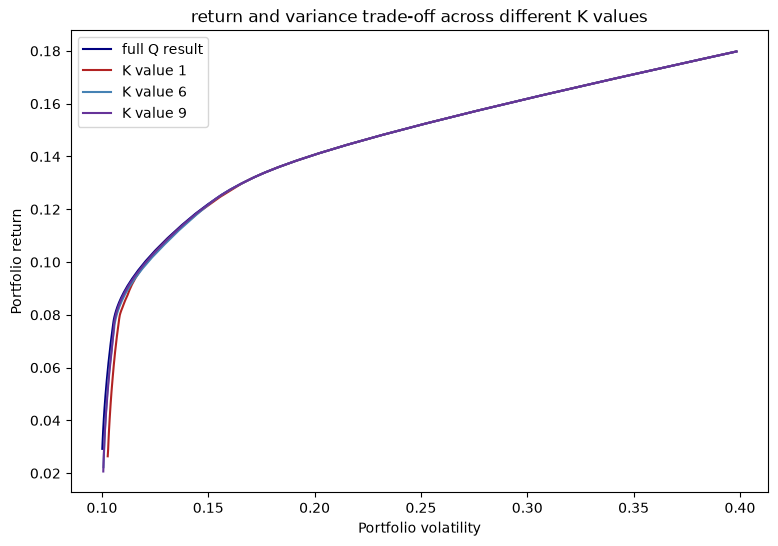

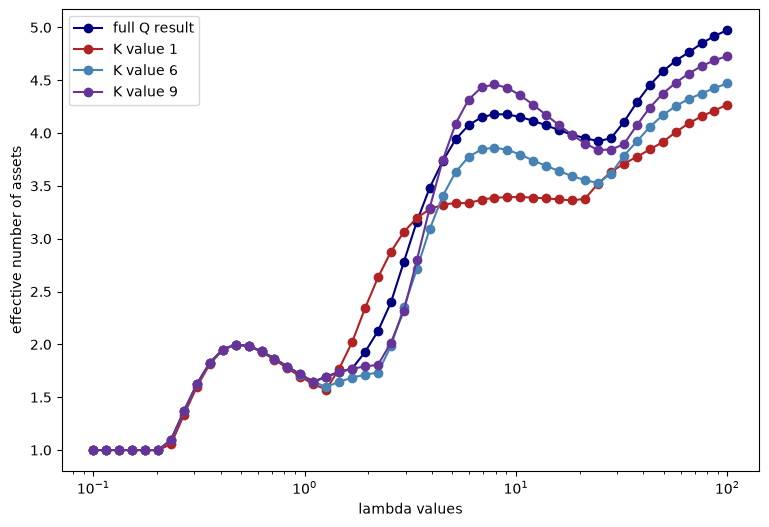

In [8]:
# Plot efficient frontier across K
evaluation(df_results_PCA,df_results)

### Discussion 5:
Taking the specific row with $K=6$ and $\lambda=3.39$, the resulting weighting vector from factor formulation and direct optimization with $Q_{PCA,k}$ are ouput below, it is evident that they are the same up to tolerence of solver rounding error$

In [9]:
# Outputting the result for a specific K and lambda to verify direct OPT and introduction of y generate the same result
print(f'-------------Result from factor formulation at K={df_results_PCA["K value"][75]}, lambda value={df_results_PCA["lambda values"][75]}-------------')
print(f'portfolio weighting are:{df_results_PCA["optimal allocation"][75]}')
print(f'PCA score (y values) are:{df_results_PCA["PC score"][75]}')
print(f'-------------Result from direct optimization with Q_PCA,K at K={df_results_PCA["K value"][75]}, lambda value={df_results_PCA["lambda values"][75]}-------------')
print(f'portfolio weighting are:{df_results_PCA["Allocation from direct OPT"][75]}')


-------------Result from factor formulation at K=6, lambda value=3.393221771895328-------------
portfolio weighting are:[0.011467204038358799, 0.09768292949261714, 0.07276836487012169, 0.0, 0.0, 7.302724183397279e-23, 4.790325595620636e-23, 1.1178072415215839e-23, 0.0, 0.0, 0.0, 0.004436871349750018, 0.1712272619714919, 0.5642204323017761, 4.099730946625193e-24, 0.07819693597588444]
PCA score (y values) are:[0.14216128967070613, -0.0522485611443323, 0.11924459886204855, -0.048010730068111275, 0.10864205970187024, -0.3512860305104581]
-------------Result from direct optimization with Q_PCA,K at K=6, lambda value=3.393221771895328-------------
portfolio weighting are:[0.01146720403835874, 0.097682929492617, 0.07276836487012202, 2.6533264031850017e-22, 0.0, 1.3587129489810388e-23, 0.0, 0.0, 1.7797622357666932e-22, 0.0, 5.272179395724043e-23, 0.004436871349749876, 0.1712272619714922, 0.5642204323017758, 0.0, 0.07819693597588431]


## Outputs for this section
- **df_results_PCA**: A dataframe with the full result from optimization under PCA (but weightings are stored as list in every cell in the column 'optimal allocation'),including the return and volatility,across 50 $\lambda$ values paired with 3 values for K.
- **dict_allocation_PCA**: a dictionary with allocations, key values are K values, value of each key is a dataframe with columns as '$\lambda$ values', and 16 assets names.

# Task 3: Validation selection and out-of-sample evaluation

## Task 3(a): Portfolio selection

Using only the **static candidates from Tasks 1--2**, choose the portfolio with the highest total validation-period P&L.

For a candidate $x$, assume that **$V_0=\$10^9$ is invested at the beginning of each day** and all positions are closed at the end of that day:

$$
\operatorname{PnL}_s(x)=V_0\,r_s^\top x,
\qquad
\operatorname{TotalPnL}(x)=\sum_s\operatorname{PnL}_s(x).
$$

The daily notional resets to $V_0$; do not compound daily returns.

### Requirements

1. Report the selected model, parameters, weights, validation total P&L, average daily return, and daily return volatility.
2. Compare the best validation candidate from each of the three model classes.

Do not use validation data to refit models or modify the candidate grids.


In [10]:
# Task 3(a): evaluate all static candidates on the validation period and select the best portfolio


## Task 3(b): Out-of-sample evaluation

Evaluate the portfolio selected in Task 3(a) on the **test period**, without changing its weights or parameters.

### Requirements

1. Report average daily test return, total test P&L, and daily return volatility.
2. Report the same statistics for the equal-weight portfolio $x_i=1/16$.
3. Compare validation and test performance.

Use the same daily-notional convention as Task 3(a). Do not use the test period for model selection.


In [11]:
# Task 3(b): final out-of-sample evaluation


# Task 4: Dynamic portfolio optimization with PCA factors

This is a separate **known-input optimization experiment** using the training data; it is not a backtest.

Divide 2017--2018 into its eight calendar quarters ($H=8$). For each quarter $t$, compute the annualized sample mean $\mu_t$ and covariance $Q_t$ using the convention in the Data section. Treat these estimates as known inputs for the following optimization problems.

Let $x_0=\mathbf1/16$ and $z_t=x_t-x_{t-1}$. As in lecture, ignore return-driven weight drift between periods.

Consider two transaction-cost functions:

$$
C_\kappa^{(1)}(z)=\kappa\|z\|_1,
\qquad
C_\kappa^{(2)}(z)=\kappa\left(\|z\|_1+\frac{\|z\|_2^2}{q}\right).
$$

Use

$$
\lambda=10,\qquad q=0.05,\qquad
\kappa\in\{0,0.05,0.2,1,4\}.
$$

Use gross turnover $\|z_t\|_1$ and include the initial trade $x_0\to x_1$. The cost parameters are model penalties, not calibrated brokerage fees.


## Task 4(a): Full-covariance dynamic optimization

For each cost model and $\kappa$, jointly solve

$$
\min_{x_1,\ldots,x_H}
\sum_{t=1}^H
\left[
\lambda x_t^\top Q_tx_t-\mu_t^\top x_t+C_\kappa(x_t-x_{t-1})
\right]
$$

subject to $x_t\ge0$ and $\mathbf1^\top x_t=1$ for all $t$.

### Requirements

1. Implement both cost models and explain why the problems are convex.
2. Compare portfolio paths, total turnover $\sum_t\|z_t\|_1$, total transaction penalty, and objective value across $\kappa$ and cost models.
3. Report $\sum_t\|z_t\|_2^2$ and $\max_{t,i}|z_{t,i}|$ to assess trade sizes.
4. Include representative path plots and discuss the results.


We jointly choose portfolios for the eight quarters of 2017–2018 under both transaction-cost models and all five prescribed penalty coefficients. Larger penalties reduce trading in this sample; at $\kappa=4$, both models keep the equal-weight starting portfolio.

Keep `Project2_returns.csv` beside this notebook and run the cells in order. This section is independent of Parts 1–3 and 4(b). The implementation follows the quarterly-input, matrix-variable, and full-horizon optimization style in `Week_4_Rebalancing_Portfolio.ipynb` and the Week 4 dynamic portfolio lecture notes.

## 1. Quarterly inputs

The CSV already contains daily returns. For each calendar quarter, use
$$\mu_t=252\bar r_t,\qquad Q_t=252\widehat\Sigma_t,$$
where the sample covariance uses denominator $N_t-1$. Set $x_0=\mathbf1/16$, $\lambda=10$, and $q=0.05$. These quarterly estimates are treated as known inputs; this is not a backtest, and return-driven weight drift is ignored.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from IPython.display import display

#preserve the assignment's asset order
asset_lst = ['GOOG', 'TSLA', 'AAPL', 'GS', 'A', 'AAP', 'MSFT', 'AMZN', 'NVDA', 'JPM', 'XOM', 'JNJ', 'PG', 'WMT', 'CAT', 'BA']
#set the prescribed risk-aversion coefficient and quadratic-cost scale
LAM, q = 10.0, 0.05
#use all five required transaction-penalty coefficients
kappa_grid = [0.0, 0.05, 0.2, 1.0, 4.0]
#label the proportional and proportional-plus-quadratic models
cost_models = ['L1', 'L1+L2sq']
#read the supplied returns with a date index
returns = pd.read_csv('Project2_returns.csv', parse_dates=['Date'], index_col='Date')
#select the training dates and required columns in chronological order
train_returns = returns.sort_index().loc['2017-01-01':'2018-12-31', asset_lst]
#follow the starter notebook's missing-value cleaning convention
train_returns = train_returns.replace([np.inf, -np.inf], np.nan).dropna()
#group the training returns into calendar quarters
quarters = list(train_returns.groupby(train_returns.index.to_period('Q')))
#store labels for the eight decision periods
periods = [str(period) for period, block in quarters]
#annualize each quarter's mean vector
mu_path = np.array([252 * block.mean().to_numpy() for period, block in quarters])
#annualize each quarter's sample covariance matrix
Q_path = np.array([252 * block.cov(ddof=1).to_numpy() for period, block in quarters])
#read the number of quarters and assets
H, n = mu_path.shape
#start with equal weights in all 16 assets
x0 = np.ones(n) / n
#verify the required sample structure and covariance definiteness
assert (H, n) == (8, 16) and min(np.linalg.eigvalsh(Q).min() for Q in Q_path) >= -1e-10
print(f'{len(train_returns)} daily observations; {periods[0]}–{periods[-1]}; {n} assets.')

502 daily observations; 2017Q1–2018Q4; 16 assets.


## 2. Joint optimization and convexity

For $z_t=x_t-x_{t-1}$, the two transaction penalties are
$$C^{(1)}_\kappa(z)=\kappa\|z\|_1,\qquad
C^{(2)}_\kappa(z)=\kappa\left(\|z\|_1+\frac{\|z\|_2^2}{q}\right).$$

For each model and $\kappa$, solve
$$\min_{x_1,\ldots,x_8}\sum_{t=1}^{8}
\left[\lambda x_t^\top Q_tx_t-\mu_t^\top x_t+C_\kappa(z_t)\right],
\qquad x_t\ge0,\quad\mathbf1^\top x_t=1.$$

**Why convex?** Each sample covariance is positive semidefinite, so its quadratic risk term is convex. Expected return is affine. The norm and squared-norm penalties are convex with nonnegative coefficients, and the constraints are linear.

`X` contains all eight portfolios. The loop builds one objective, and the solver chooses the entire path jointly. The first trade is from `x0`; subsequent trades use adjacent portfolio decisions.

In [13]:
#solve one full-horizon problem for a chosen penalty and cost model
def solve_full_horizon(mu_path, Q_path, x0, kappa, cost_model):
    #create one portfolio row for each quarter
    X = cp.Variable(mu_path.shape)
    #start the total objective
    objective = 0
    #add every quarter to the same optimization problem
    for t in range(len(mu_path)):
        #include the initial trade and ignore return-driven weight drift
        z = X[t] - (x0 if t == 0 else X[t - 1])
        #include the proportional penalty in both models
        cost = kappa * cp.norm1(z)
        #add squared individual trades for the second model
        if cost_model == 'L1+L2sq':
            #divide the squared norm by the prescribed q
            cost += (kappa / q) * cp.sum_squares(z)
        #add risk, negative expected return, and transaction penalty
        objective += LAM * cp.quad_form(X[t], cp.psd_wrap(Q_path[t])) - mu_path[t] @ X[t] + cost
    #require long-only, fully invested portfolios in every quarter
    problem = cp.Problem(cp.Minimize(objective), [X >= 0, cp.sum(X, axis=1) == 1])
    #solve the joint convex problem with consistent numerical tolerances
    problem.solve(solver=cp.OSQP, eps_abs=1e-9, eps_rel=1e-9, max_iter=200000, warm_start=False)
    #check solver success before using the returned weights
    assert problem.status == cp.OPTIMAL
    #allow only negligible numerical violations of the constraints
    assert X.value.min() >= -1e-6 and np.max(np.abs(X.value.sum(axis=1) - 1)) < 1e-6
    #return the complete path and the minimized objective
    return X.value.copy(), float(problem.value)

## 3. Results for both cost models

The table reports total gross turnover $\sum_t\|z_t\|_1$, total penalty, objective value, squared-trade sum $\sum_t\|z_t\|_2^2$, and largest individual trade $\max_{t,i}|z_{t,i}|$. All include the initial trade. Turnover has **no factor of one-half**; a maximum trade of 0.10 means a 10 percentage-point weight change.

In [14]:
#store all ten paths for plotting and later comparisons
full_solutions = {}
#collect one table row per model and penalty coefficient
rows = []
#run both transaction-cost models
for cost_model in cost_models:
    #run every required coefficient
    for kappa in kappa_grid:
        #optimize all eight quarterly portfolios jointly
        X, objective_value = solve_full_horizon(mu_path, Q_path, x0, kappa, cost_model)
        #save the path under its matching model and coefficient
        full_solutions[(cost_model, kappa)] = X
        #compute all trades, including the initial rebalance
        Z = np.diff(np.vstack([x0, X]), axis=0)
        #add absolute purchases and sales over all periods and assets
        turnover = np.abs(Z).sum()
        #sum squared individual trades
        squared_trades = np.square(Z).sum()
        #calculate the total proportional penalty
        penalty = kappa * turnover
        #include the quadratic component when using model 2
        if cost_model == 'L1+L2sq':
            #apply the same q scaling as the optimizer
            penalty += (kappa / q) * squared_trades
        #record the five required metrics for this case
        rows.append([cost_model, kappa, turnover, penalty, objective_value, squared_trades, np.abs(Z).max()])
#label the results and index them by model and coefficient
full_results = pd.DataFrame(rows, columns=['Cost model', 'kappa', 'Turnover', 'Penalty', 'Objective', 'Squared trades', 'Max trade']).set_index(['Cost model', 'kappa'])
display(full_results.round(6))

Turnover   Penalty  Objective  Squared trades  Max trade
Cost model kappa                                                           
L1         0.00   13.486835  0.000000  -1.954267        6.142780   0.766680
           0.05   10.856179  0.542809  -1.335903        3.933846   0.750401
           0.20    4.957703  0.991541  -0.205018        1.112533   0.655527
           1.00    0.776575  0.776575   1.219014        0.047821   0.089163
           4.00    0.000000  0.000000   1.885590        0.000000   0.000000
L1+L2sq    0.00   13.486835  0.000000  -1.954267        6.142780   0.766680
           0.05    4.554785  0.620560  -0.345039        0.392821   0.210246
           0.20    1.785067  0.640551   0.521629        0.070884   0.081753
           1.00    0.444630  0.582747   1.514352        0.006906   0.025725
           4.00    0.000000  0.000000   1.885590        0.000000   0.000000

## 4. Representative portfolio paths

These heatmaps compare $\kappa=0,0.2,4$ under both models. Each includes the equal-weight starting allocation and all eight quarterly portfolios. Every panel uses the same color scale; all five coefficients remain in the table above.

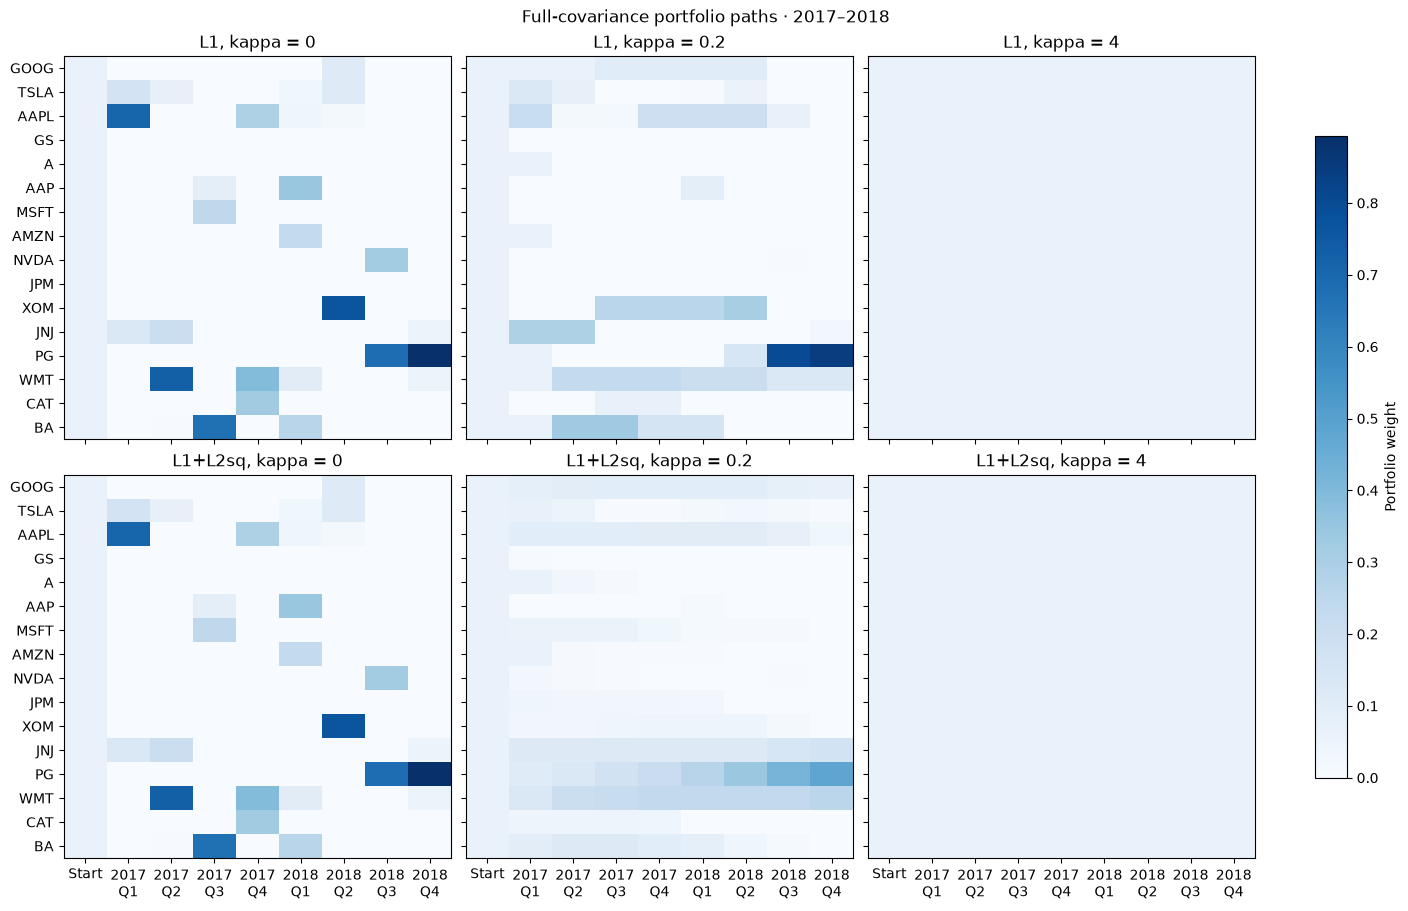

In [15]:
#show representative zero, intermediate, and high penalties
plot_kappas = [0.0, 0.2, 4.0]
#label the initial allocation and quarterly decisions
labels = ['Start'] + [period.replace('Q', '\nQ') for period in periods]
color_max = max(full_solutions[(m, k)].max() for m in cost_models for k in plot_kappas)
#create a row per model and a column per representative coefficient
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True, layout='constrained')
#draw the paths for each transaction model
for i, cost_model in enumerate(cost_models):
    #draw each representative coefficient in its own panel
    for j, kappa in enumerate(plot_kappas):
        #include the starting portfolio before the eight optimized rows
        path = np.vstack([x0, full_solutions[(cost_model, kappa)]])
        #display assets as rows and decision periods as columns
        heatmap = axes[i, j].imshow(path.T, aspect='auto', cmap='Blues', vmin=0, vmax=color_max)
        #identify the model and coefficient
        axes[i, j].set_title(f'{cost_model}, kappa = {kappa:g}')
        #label all 16 assets in order
        axes[i, j].set_yticks(range(n), asset_lst)
        #label the initial portfolio and all quarterly decisions
        axes[i, j].set_xticks(range(H + 1), labels)
#label the shared color scale in portfolio weight units
fig.colorbar(heatmap, ax=axes, label='Portfolio weight', shrink=0.8)
fig.suptitle('Full-covariance portfolio paths · 2017–2018')
plt.show()

## 5. Discussion

- **No transaction penalty:** at $\kappa=0$, both models give the same solution, with turnover **13.486835** and objective **−1.954267**. The paths change substantially between quarters because trading is unpenalized.
- **Effect of increasing $\kappa$:** trading falls under both models in this sample. At $\kappa=4$, both paths stay at the equal-weight starting portfolio within numerical tolerance, with essentially zero turnover and penalty and objective **1.885590**. Within either model, the optimized objective cannot decrease as $\kappa$ rises because every feasible path receives a weakly larger nonnegative penalty. The paid penalty itself need not increase monotonically.
- **Effect of the quadratic term:** at $\kappa=0.2$, adding squared-trade costs reduces turnover from **4.957703 to 1.785067**, squared trades from **1.112533 to 0.070884**, and the largest trade from **65.55 to 8.18 percentage points**. The path adjusts more gradually. Total penalties are **0.991541** versus **0.640551**, and objectives are **−0.205018** versus **0.521629**. The objective definitions differ between models, so these values do not establish that one portfolio is universally better.

The penalties are model costs rather than calibrated brokerage fees. These known-input objective values do not measure realized profit or out-of-sample performance.

## Task 4(b): Dynamic PCA factor model

For each quarter, construct

$$
Q_{t,\mathrm{PCA},K}
=W_{t,K}\Lambda_{t,K}W_{t,K}^\top+D_{t,K},
\qquad
y_t=W_{t,K}^\top x_t,
$$

using the same procedure as Task 2(b).

For either transaction-cost model, solve

$$
\min_{\{x_t,y_t\}_{t=1}^H}
\sum_{t=1}^H
\left[
\lambda(y_t^\top\Lambda_{t,K}y_t+x_t^\top D_{t,K}x_t)
-\mu_t^\top x_t+C_\kappa(x_t-x_{t-1})
\right]
$$

subject to

$$
x_t\ge0,\qquad \mathbf1^\top x_t=1,\qquad y_t=W_{t,K}^\top x_t.
$$

### Requirements

1. Implement for the three values of $K$ in $\{2,5,8\}$. For each, run both cost models and the prescribed $\kappa$ values.
2. Compare paths, turnover, largest individual trade, and runtime with Task 4(a).
3. For each PCA-generated path, evaluate the **full-covariance dynamic objective with the same cost model**, and compare it with the full-covariance optimum. Report the objective gap and the path distance $\sum_t\|x_t^{\mathrm{PCA}}-x_t^{\mathrm{full}}\|_1$.
4. Verify agreement when $K=16$ for at least one positive $\kappa$ under each cost model.
5. Discuss how $K$ affects covariance approximation and portfolio decisions.


In [16]:
# Task 4(b): your dynamic PCA factor-model implementation
